In [1]:
import pandas as pd

opisy = pd.read_feather("/Users/explorjus/Python-projekty/fly_autopilot/data/body-annotations-male-cns-v1.0-minconf-0.5.feather")
opisy.head()

,assignedOlHex1,assignedOlHex2,bodyId,flywireType,group,instance,somaSide,statusLabel,superclass,type,...,entryNerve,mancSerial,mcnsSerial,serialMotif,fruDsx,exitNerve,receptorType,somaLocation,tosomaLocation,status
0,NaN,NaN,10001,DNp01,10001.0,DNp01(GF)_R,R,Roughly traced,descending_neuron,DNp01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[37124, 22258, 36274]",None,Traced
1,NaN,NaN,10002,OCG01d,10002.0,OCG01d_L,L,Roughly traced,visual_projection,OCG01d,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[50214, 10279, 27497]",None,Traced
2,NaN,NaN,10003,VCH,10003.0,VCH_R,R,Prelim Roughly traced,visual_centrifugal,VCH,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[46716, 21029, 15714]",None,Traced
3,NaN,NaN,10005,AOTU019,10005.0,AOTU019_R,R,Roughly traced,cb_intrinsic,AOTU019,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[41190, 18491, 12885]",None,Traced
4,NaN,NaN,10006,"VS1,VS2,VS3,VS4,VS5,VS6,VS7,VS8",10006.0,VS_L,L,Prelim Roughly traced,visual_projection,VS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[69604, 28368, 42459]",None,Traced


In [2]:
opisy.columns

Index(['assignedOlHex1', 'assignedOlHex2', 'bodyId', 'flywireType', 'group',
       'instance', 'somaSide', 'statusLabel', 'superclass', 'type', 'vfbId',
       'hemibrainType', 'itoleeHl', 'supertype', 'birthtime', 'mancBodyid',
       'mancGroup', 'mancType', 'subclass', 'synonyms', 'class', 'rootSide',
       'somaNeuromere', 'trumanHl', 'dimorphism', 'matchingNotes',
       'entryNerve', 'mancSerial', 'mcnsSerial', 'serialMotif', 'fruDsx',
       'exitNerve', 'receptorType', 'somaLocation', 'tosomaLocation',
       'status'],
      dtype='object')

In [7]:
opisy.shape

(211577, 36)

In [13]:
opisy["superclass"].value_counts()

superclass
ol_intrinsic             89403
cb_intrinsic             32164
vnc_intrinsic            13161
visual_projection         9201
vnc_sensory               6370
ol_sensory                6098
cb_sensory                4868
ascending_neuron          1846
descending_neuron         1314
vnc_motor                  708
visual_centrifugal         563
sensory_ascending          537
cb_motor                   107
vnc_efferent                94
cb_endocrine                72
ENS                         50
vnc_tbc                     38
vnc_sensory_tbc             36
vnc_endocrine               22
cb_sensory_tbc              14
sensory_descending          12
efferent_ascending           8
efferent_descending          4
cb_efferent                  4
visual_projection_tbc        2
sensory_ascending_tbc        2
descending_neuron_tbc        2
Name: count, dtype: int64

In [21]:
opisy["superclass"].isin(["visual_projection"])

np.int64(9201)

In [29]:
wejscia = opisy[opisy["type"].isin(["HSN", "HSE", "HSS", "VS"])]
print(len(wejscia))

wejscia = wejscia[["bodyId", "type", "somaSide"]]
wejscia

24


,bodyId,type,somaSide
4,10006,VS,L
8,10012,VS,R
10,10015,HSN,R
11,10016,HSE,R
17,10023,HSS,R
27,10034,HSE,L
29,10037,VS,R
62,10073,VS,L
100,10112,VS,R
148,10161,VS,L


In [32]:
wejscia.to_csv("/Users/explorjus/Python-projekty/fly_autopilot/data/processed/wejscia_hs_vs.csv", index=False)

In [33]:
import pyarrow.feather as feather

sciezka_graf = "/Users/explorjus/Python-projekty/fly_autopilot/data/connectome-weights-male-cns-v1.0-minconf-0.5.feather"
feather.read_table(sciezka_graf, memory_map=True).schema

body_pre: int64
body_post: int64
weight: int64
-- schema metadata --
pandas: '{"index_columns": [{"kind": "range", "name": null, "start": 0, "' + 604

In [34]:
graf = pd.read_feather(sciezka_graf)
graf.shape

(151856684, 3)

In [35]:
z_wejsc = graf[graf["body_pre"].isin(wejscia["bodyId"])]

print(len(z_wejsc))
print(z_wejsc["body_post"].nunique())

28562
26827


In [37]:
z_wejsc["weight"].describe()

In [40]:
silne = z_wejsc[z_wejsc["weight"] >= 5]
print(len(silne))

725


In [41]:
z_wejsc["weight"].describe()
silne = z_wejsc[z_wejsc["weight"] >= 5]
print(len(silne))
silne_opisane = silne.merge(
    opisy[["bodyId", "type", "superclass"]],
    left_on="body_post",
    right_on="bodyId",
    how="left"
)
silne_opisane["superclass"].value_counts()

725


superclass
cb_intrinsic          313
descending_neuron     132
visual_centrifugal     80
cb_motor               63
visual_projection      37
ol_intrinsic            7
Name: count, dtype: int64

In [42]:
dn = silne_opisane[silne_opisane["superclass"] == "descending_neuron"]

ranking = dn.groupby("type")["weight"].sum().sort_values(ascending=False)
ranking.head(15)

type
DNp20      936
DNp15      501
DNp17      262
DNge043    247
DNp53      195
DNp18      166
DNb06      166
DNa02      133
DNp22      124
DNg41       92
DNae002     78
DNge107     69
DNae010     59
DNbe001     58
DNge086     40
Name: weight, dtype: int64

In [44]:
opis_mini = opisy[["bodyId", "type", "somaSide", "superclass"]]

pol = silne.merge(opis_mini.add_suffix("_pre"), left_on="body_pre", right_on="bodyId_pre", how="left")
pol = pol.merge(opis_mini.add_suffix("_post"), left_on="body_post", right_on="bodyId_post", how="left")

pol.head()

,body_pre,body_post,weight,bodyId_pre,type_pre,somaSide_pre,superclass_pre,bodyId_post,type_post,somaSide_post,superclass_post
0,10015,11215,138,10015,HSN,R,visual_projection,11215.0,DNp15,R,descending_neuron
1,10181,12069,126,10181,HSN,L,visual_projection,12069.0,DNp15,L,descending_neuron
2,10016,11215,122,10016,HSE,R,visual_projection,11215.0,DNp15,R,descending_neuron
3,10012,11010,95,10012,VS,R,visual_projection,11010.0,V1,R,visual_centrifugal
4,10006,10854,94,10006,VS,L,visual_projection,10854.0,V1,L,visual_centrifugal


In [45]:
cele = ["DNp20", "DNp22", "DNp15"]
dn_cel = pol[pol["type_post"].isin(cele)]

dn_cel.groupby(["type_post", "somaSide_post"])["weight"].sum()

type_post  somaSide_post
DNp15      L                218
           R                283
DNp20      L                494
           R                442
DNp22      L                 51
           R                 73
Name: weight, dtype: int64

In [46]:
dn_cel.groupby(["type_post", "somaSide_post", "type_pre", "somaSide_pre"])["weight"].sum()

type_post  somaSide_post  type_pre  somaSide_pre
DNp15      L              HSE       L                78
                          HSN       L               126
                          HSS       L                14
           R              HSE       R               122
                          HSN       R               138
                          HSS       R                23
DNp20      L              VS        L               494
           R              VS        R               442
DNp22      L              VS        L                51
           R              VS        R                73
Name: weight, dtype: int64

In [47]:
wyjscia = opisy[opisy["type"].isin(cele)][["bodyId", "type", "somaSide"]]
print(len(wyjscia))
wyjscia

wyjscia.to_csv("/Users/explorjus/Python-projekty/fly_autopilot/data/processed/wyjscia_dn.csv", index=False)

6


In [48]:
mini_ids = pd.concat([wejscia["bodyId"], wyjscia["bodyId"]])

podsiec = graf[graf["body_pre"].isin(mini_ids) & graf["body_post"].isin(mini_ids)]

print(len(podsiec))
podsiec.sort_values("weight", ascending=False).head(20)

123


,body_pre,body_post,weight
26056,10015,11215,138
32431,10181,12069,126
35290,10016,11215,122
63200,10766,10059,94
70025,522957,10162,90
72037,518028,10162,88
75696,10284,10059,86
93815,10034,12069,78
102075,522954,10162,75
106079,19588,10162,73


In [49]:
podsiec_opis = podsiec.merge(opis_mini.add_suffix("_pre"), left_on="body_pre", right_on="bodyId_pre", how="left")
podsiec_opis = podsiec_opis.merge(opis_mini.add_suffix("_post"), left_on="body_post", right_on="bodyId_post", how="left")

podsiec_opis.groupby(["type_pre", "type_post"])["weight"].agg(["count", "sum"])

count  sum
type_pre type_post            
DNp15    DNp20          2   24
         DNp22          1    2
         HSS            1    1
DNp20    DNp15          1    7
         VS             2    4
DNp22    VS             1    1
HSE      DNp15          2  200
         HSN            2    3
         HSS            2    2
         VS             1    2
HSN      DNp15          2  264
         HSE            1    4
         VS             6   14
HSS      DNp15          2   37
         HSE            1    2
         VS             1    1
VS       DNp20         14  936
         DNp22          8  131
         HSE            1    1
         HSS            2    5
         VS            70  237

In [50]:
nt = pd.read_feather("/Users/explorjus/Python-projekty/fly_autopilot/data/body-neurotransmitters-male-cns-v1.0.feather")
print(nt.columns)
nt.head()

Index(['body', 'cell_type', 'total_nt_predictions', 'predicted_nt_confidence',
       'predicted_nt', 'ground_truth', 'celltype_total_nt_predictions',
       'celltype_predicted_nt', 'celltype_predicted_nt_confidence',
       'consensus_nt'],
      dtype='object')


,body,cell_type,total_nt_predictions,predicted_nt_confidence,predicted_nt,ground_truth,celltype_total_nt_predictions,celltype_predicted_nt,celltype_predicted_nt_confidence,consensus_nt
0,10001,DNp01,1015,0.500496,acetylcholine,NaN,1991,acetylcholine,0.528263,acetylcholine
1,10002,OCG01d,1443,0.955895,acetylcholine,NaN,2818,acetylcholine,0.956476,acetylcholine
2,10003,VCH,4425,0.879325,gaba,gaba,8721,gaba,0.874799,gaba
3,10005,AOTU019,2837,0.835076,gaba,gaba,5673,gaba,0.830504,gaba
4,10006,VS,426,0.904134,acetylcholine,acetylcholine,5260,acetylcholine,0.820038,acetylcholine


In [51]:
nt_mini = nt[nt["body"].isin(mini_ids)][["body", "cell_type", "consensus_nt"]]
nt_mini.groupby(["cell_type", "consensus_nt"]).size()

cell_type  consensus_nt 
DNp15      acetylcholine     2
DNp20      acetylcholine     2
DNp22      acetylcholine     2
HSE        acetylcholine     2
HSN        acetylcholine     2
HSS        acetylcholine     2
VS         acetylcholine    18
dtype: int64

In [52]:
import numpy as np

ids = mini_ids.to_numpy()
indeks = {b: i for i, b in enumerate(ids)}   # bodyId -> numer 0..29
N = len(ids)

W = np.zeros((N, N))
for pre, post, w in podsiec[["body_pre", "body_post", "weight"]].itertuples(index=False):
    W[indeks[post], indeks[pre]] = w

info = opisy.set_index("bodyId").loc[ids]
nazwy = (info["type"] + "_" + info["somaSide"]).to_numpy()
print(N, W.sum())

30 1878.0


In [53]:
def symuluj(pobudzone, czas_ms=1000, czestotliwosc_hz=150, dt=0.1, seed=0):
    rng = np.random.default_rng(seed)

    # parametry z modelu Shiu i wsp. (2024)
    v_spocz, v_prog = -52.0, -45.0     # napięcie spoczynkowe i próg [mV]
    tau_m, tau_syn = 20.0, 5.0         # stałe czasowe błony i synapsy [ms]
    refrakcja = 2.2                    # czas "martwy" po impulsie [ms]
    w_syn = 0.275                      # siła jednej synapsy [mV]
    f_poi = 250                        # siła sztucznego wejścia z zewnątrz

    v = np.full(N, v_spocz)            # napięcie każdego neuronu
    g = np.zeros(N)                    # prąd synaptyczny każdego neuronu
    blokada = np.zeros(N)              # ile ms zostało do końca refrakcji
    impulsy = np.zeros(N, dtype=int)   # licznik impulsów

    p_wejscia = czestotliwosc_hz * dt / 1000   # szansa impulsu wejściowego w jednym kroku

    for _ in range(int(czas_ms / dt)):
        # 1. wejście z zewnątrz: losowe impulsy tylko do pobudzanych neuronów
        losowe = rng.random(N) < p_wejscia
        g += w_syn * f_poi * (losowe & pobudzone)

        # 2. integrate + leaky: napięcie rośnie od g i "przecieka" do spoczynku
        v += dt * (v_spocz - v + g) / tau_m
        g -= dt * g / tau_syn
        v[blokada > 0] = v_spocz
        blokada -= dt

        # 3. fire: kto przekroczył próg, strzela i wraca do spoczynku
        strzal = v >= v_prog
        impulsy += strzal
        v[strzal] = v_spocz
        blokada[strzal] = refrakcja

        # 4. impulsy płyną do odbiorców przez macierz połączeń
        g += w_syn * (W @ strzal)

    return impulsy / (czas_ms / 1000)   # częstotliwość w Hz

In [54]:
lewe_vs = (info["type"].to_numpy() == "VS") & (info["somaSide"].to_numpy() == "L")

czestotliwosci = symuluj(lewe_vs)

wynik = pd.DataFrame({"neuron": nazwy, "Hz": czestotliwosci})
wynik.groupby("neuron")["Hz"].mean().round(1)

neuron
DNp15_L      0.0
DNp15_R      0.0
DNp20_L    279.0
DNp20_R      0.0
DNp22_L     52.0
DNp22_R      0.0
HSE_L        0.0
HSE_R        0.0
HSN_L        0.0
HSN_R        0.0
HSS_L        0.0
HSS_R        0.0
VS_L       166.9
VS_R         0.0
Name: Hz, dtype: float64

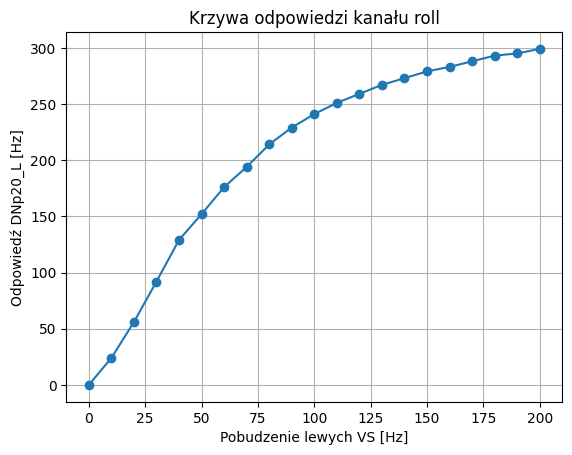

In [55]:
import matplotlib.pyplot as plt

wejscia_hz = range(0, 201, 10)
odpowiedz = []

for hz in wejscia_hz:
    czest = symuluj(lewe_vs, czestotliwosc_hz=hz)
    odpowiedz.append(czest[nazwy == "DNp20_L"].mean())

plt.plot(list(wejscia_hz), odpowiedz, marker="o")
plt.xlabel("Pobudzenie lewych VS [Hz]")
plt.ylabel("Odpowiedź DNp20_L [Hz]")
plt.title("Krzywa odpowiedzi kanału roll")
plt.grid(True)
plt.show()

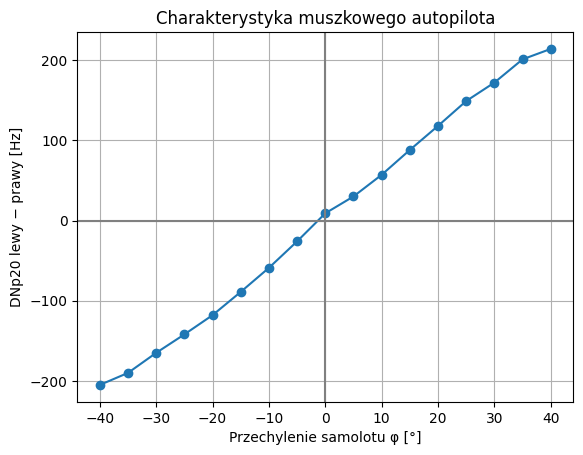

In [56]:
typy = info["type"].to_numpy()
strony = info["somaSide"].to_numpy()
vs_l = (typy == "VS") & (strony == "L")
vs_r = (typy == "VS") & (strony == "R")

baza = 40   # Hz przy locie poziomym
k = 1.0     # ile Hz na 1 stopień przechylenia

katy = list(range(-40, 41, 5))
roznice = []

for phi in katy:
    hz = np.zeros(N)
    hz[vs_l] = max(baza + k * phi, 0)
    hz[vs_r] = max(baza - k * phi, 0)

    czest = symuluj(vs_l | vs_r, czestotliwosc_hz=hz)
    lewy = czest[nazwy == "DNp20_L"].mean()
    prawy = czest[nazwy == "DNp20_R"].mean()
    roznice.append(lewy - prawy)

plt.plot(katy, roznice, marker="o")
plt.axhline(0, color="gray")
plt.axvline(0, color="gray")
plt.xlabel("Przechylenie samolotu φ [°]")
plt.ylabel("DNp20 lewy − prawy [Hz]")
plt.title("Charakterystyka muszkowego autopilota")
plt.grid(True)
plt.show()

In [57]:
folder = "/Users/explorjus/Python-projekty/fly_autopilot/data/processed"

podsiec[["body_pre", "body_post", "weight"]].to_csv(f"{folder}/podsiec.csv", index=False)
info.reset_index()[["bodyId", "type", "somaSide"]].to_csv(f"{folder}/neurony.csv", index=False)

In [59]:
import sys
sys.path.append("/Users/explorjus/Python-projekty/fly_autopilot/src")
from mozg import Mozg

mozg = Mozg.z_plikow("/Users/explorjus/Python-projekty/fly_autopilot/data/processed")

hz = np.zeros(mozg.N)
hz[mozg.maska("VS_L")] = 60   # przechylenie φ = +20°: 40 + 20
hz[mozg.maska("VS_R")] = 20   #                        40 − 20

wyniki = [mozg.krok(50, hz) for _ in range(20)]   # 20 okien po 50 ms = 1 s
srednio = np.mean(wyniki, axis=0)

lewy = srednio[mozg.maska("DNp20_L")].mean()
prawy = srednio[mozg.maska("DNp20_R")].mean()
print(f"DNp20 lewy − prawy: {lewy - prawy:.1f} Hz")
%timeit mozg.krok(50, hz)

DNp20 lewy − prawy: 118.0 Hz
5.39 ms ± 486 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [3]:
import sys
sys.path.append("/Users/explorjus/Python-projekty/fly_autopilot/src")

from xplane import XPlane
import time

xp = XPlane("192.168.1.107")   # <- wpisz adres IP komputera z X-Plane
xp.subskrybuj("sim/flightmodel/position/phi")     # przechylenie
xp.subskrybuj("sim/flightmodel/position/theta")   # pochylenie

try:
    koniec = time.time() + 10   # przez 10 sekund
    while time.time() < koniec:
        w = xp.odbierz()
        print(f"przechylenie: {w.get('sim/flightmodel/position/phi', 0):6.1f}°   "
              f"pochylenie: {w.get('sim/flightmodel/position/theta', 0):6.1f}°")
finally:
    xp.zakoncz()

przechylenie:   -8.0°   pochylenie:   10.9°
przechylenie:   -8.1°   pochylenie:   10.9°
przechylenie:   -8.2°   pochylenie:   10.8°
przechylenie:   -8.2°   pochylenie:   10.8°
przechylenie:   -8.3°   pochylenie:   10.8°
przechylenie:   -8.4°   pochylenie:   10.8°
przechylenie:   -8.5°   pochylenie:   10.7°
przechylenie:   -8.5°   pochylenie:   10.7°
przechylenie:   -8.6°   pochylenie:   10.7°
przechylenie:   -8.7°   pochylenie:   10.7°
przechylenie:   -8.8°   pochylenie:   10.6°
przechylenie:   -8.8°   pochylenie:   10.6°
przechylenie:   -8.9°   pochylenie:   10.6°
przechylenie:   -9.0°   pochylenie:   10.5°
przechylenie:   -9.0°   pochylenie:   10.5°
przechylenie:   -9.1°   pochylenie:   10.5°
przechylenie:   -9.2°   pochylenie:   10.4°
przechylenie:   -9.2°   pochylenie:   10.4°
przechylenie:   -9.3°   pochylenie:   10.4°
przechylenie:   -9.4°   pochylenie:   10.3°
przechylenie:   -9.5°   pochylenie:   10.3°
przechylenie:   -9.6°   pochylenie:   10.3°
przechylenie:   -9.6°   pochylen

In [4]:
import pandas as pd
import numpy as np

DANE = "/Users/explorjus/Python-projekty/fly_autopilot/data"

opisy = pd.read_feather(f"{DANE}/body-annotations-male-cns-v1.0-minconf-0.5.feather")
graf = pd.read_feather(f"{DANE}/connectome-weights-male-cns-v1.0-minconf-0.5.feather")
wyjscia = pd.read_csv(f"{DANE}/processed/wyjscia_dn.csv")

opis_mini = opisy[["bodyId", "type", "somaSide", "superclass", "class"]]

In [5]:
dnp20 = wyjscia[wyjscia["type"] == "DNp20"]["bodyId"]

do_dnp20 = graf[graf["body_post"].isin(dnp20) & (graf["weight"] >= 5)]
do_dnp20 = do_dnp20.merge(opis_mini.add_suffix("_pre"), left_on="body_pre", right_on="bodyId_pre", how="left")

do_dnp20.groupby(["superclass_pre", "class_pre", "type_pre"], dropna=False)["weight"].sum() \
        .sort_values(ascending=False).head(25)

superclass_pre     class_pre  type_pre
visual_projection  NaN        OCG01d      1481
                              OCG01e       993
                              VS           936
                              MeVP9        890
                              OCG01a       720
                              OCG01c       686
cb_intrinsic       NaN        AMMC013      632
visual_projection  NaN        VST2         580
cb_intrinsic       NaN        GNG416       363
                              PS331        318
descending_neuron  NaN        DNge087      253
cb_intrinsic       NaN        PS303        197
visual_projection  NaN        MeVP55       164
NaN                NaN        NaN          133
cb_intrinsic       NaN        GNG124        94
                              PS074         85
                              PS341         84
                              GNG310        61
descending_neuron  NaN        DNg81         58
cb_intrinsic       NaN        CB1792        55
                     

In [6]:
maska = opisy[["type", "class", "superclass"]].astype(str) \
    .apply(lambda kolumna: kolumna.str.contains("ocell|OCG|OCC", case=False)) \
    .any(axis=1)

opisy[maska].groupby(["superclass", "class", "type"], dropna=False).size()

superclass          class           type          
cb_sensory          mechanosensory  BM_vOcci_vPoOr    26
visual_centrifugal  NaN             OCC01b             2
                                    OCC02a             6
                                    OCC02b            16
                                    OCG06              2
visual_projection   NaN             OCG01a             2
                                    OCG01b             2
                                    OCG01c             2
                                    OCG01d             2
                                    OCG01e             2
                                    OCG01f             2
                                    OCG02b             2
                                    OCG02c             4
                                    OCG03              2
dtype: int64

In [7]:
ocg = ["OCG01a", "OCG01c", "OCG01d", "OCG01e"]

strona_dn = wyjscia.rename(columns={"bodyId": "body_post", "somaSide": "strona_DN"})[["body_post", "strona_DN"]]

ocg_do_dn = do_dnp20[do_dnp20["type_pre"].isin(ocg)].merge(strona_dn, on="body_post")
ocg_do_dn.groupby(["type_pre", "somaSide_pre", "strona_DN"], dropna=False)["weight"].sum()

type_pre  somaSide_pre  strona_DN
OCG01a    L             L            348
          R             R            372
OCG01c    L             L            318
          R             R            368
OCG01d    L             R            790
          R             L            691
OCG01e    L             L            491
          R             R            502
Name: weight, dtype: int64

In [8]:
nt = pd.read_feather(f"{DANE}/body-neurotransmitters-male-cns-v1.0.feather")
nt[nt["cell_type"].isin(ocg)][["body", "cell_type", "consensus_nt"]]

,body,cell_type,consensus_nt
1,10002,OCG01d,acetylcholine
218,10235,OCG01d,acetylcholine
357,10381,OCG01e,acetylcholine
447,10478,OCG01e,acetylcholine
1999,12127,OCG01c,glutamate
154933,512190,OCG01a,glutamate
156029,514165,OCG01a,glutamate
159103,519267,OCG01c,glutamate


In [9]:
wejscia = pd.read_csv(f"{DANE}/processed/wejscia_hs_vs.csv")
ocg_neurony = opisy[opisy["type"].isin(ocg)][["bodyId", "type", "somaSide"]]

neurony = pd.concat([wejscia, wyjscia, ocg_neurony], ignore_index=True)
print("neurony:", len(neurony))          # powinno być 38 (24 + 6 + 8)

ids = neurony["bodyId"]
podsiec = graf[graf["body_pre"].isin(ids) & graf["body_post"].isin(ids)]
print("połączenia:", len(podsiec))

# znak każdego neuronu z jego neuroprzekaźnika
znak_nt = {"acetylcholine": 1, "gaba": -1, "glutamate": -1}
nt_mini = nt[["body", "consensus_nt"]].rename(columns={"body": "bodyId"})
neurony = neurony.merge(nt_mini, on="bodyId", how="left")
neurony["znak"] = neurony["consensus_nt"].map(znak_nt).fillna(1).astype(int)

print(neurony[["type", "consensus_nt", "znak"]].value_counts())

neurony[["bodyId", "type", "somaSide", "znak"]].to_csv(f"{DANE}/processed/neurony.csv", index=False)
podsiec[["body_pre", "body_post", "weight"]].to_csv(f"{DANE}/processed/podsiec.csv", index=False)

neurony: 38
połączenia: 191
type    consensus_nt   znak
VS      acetylcholine   1      18
HSN     acetylcholine   1       2
HSE     acetylcholine   1       2
HSS     acetylcholine   1       2
DNp20   acetylcholine   1       2
DNp15   acetylcholine   1       2
DNp22   acetylcholine   1       2
OCG01d  acetylcholine   1       2
OCG01e  acetylcholine   1       2
OCG01c  glutamate      -1       2
OCG01a  glutamate      -1       2
Name: count, dtype: int64


In [10]:
        indeks = {b: i for i, b in enumerate(neurony["bodyId"])}
        N = len(neurony)

        # znak neuronu wysyłającego: +1 pobudza, -1 hamuje (zasada Dale'a)
        if "znak" in neurony.columns:
            znaki = neurony["znak"].to_numpy()
        else:
            znaki = np.ones(N)

        W = np.zeros((N, N))
        for pre, post, w in polaczenia[["body_pre", "body_post", "weight"]].itertuples(index=False):
            W[indeks[post], indeks[pre]] = w * znaki[indeks[pre]]

NameError: name 'polaczenia' is not defined

neurony: 38   połączenia hamujące: 18


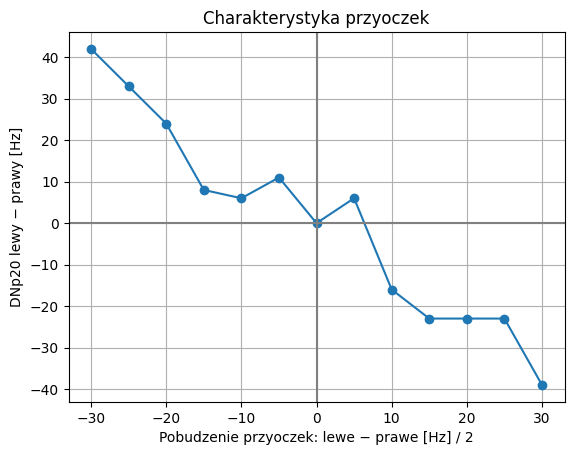

In [1]:
import sys
sys.path.append("/Users/explorjus/Python-projekty/fly_autopilot/src")

import numpy as np
import matplotlib.pyplot as plt
from mozg import Mozg

DANE = "/Users/explorjus/Python-projekty/fly_autopilot/data"
mozg = Mozg.z_plikow(f"{DANE}/processed")
print("neurony:", mozg.N, "  połączenia hamujące:", (mozg.W < 0).sum())

ocg_l = np.isin(mozg.nazwy, ["OCG01a_L", "OCG01c_L", "OCG01d_L", "OCG01e_L"])
ocg_r = np.isin(mozg.nazwy, ["OCG01a_R", "OCG01c_R", "OCG01d_R", "OCG01e_R"])

asymetrie = list(range(-30, 31, 5))
roznice = []

for a in asymetrie:
    mozg.reset()
    hz = np.zeros(mozg.N)
    hz[ocg_l] = 40 + a      # a > 0: lewe przyoczko pobudzane mocniej
    hz[ocg_r] = 40 - a
    czest = np.mean([mozg.krok(50, hz) for _ in range(20)], axis=0)
    roznice.append(czest[mozg.maska("DNp20_L")].mean() - czest[mozg.maska("DNp20_R")].mean())

plt.plot(asymetrie, roznice, marker="o")
plt.axhline(0, color="gray")
plt.axvline(0, color="gray")
plt.xlabel("Pobudzenie przyoczek: lewe − prawe [Hz] / 2")
plt.ylabel("DNp20 lewy − prawy [Hz]")
plt.title("Charakterystyka przyoczek")
plt.grid(True)
plt.show()